In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_diabetes
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error

import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.stats.stattools import durbin_watson

import scipy.stats as stats

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# Load the diabetes dataset
diabetes = load_diabetes()

# Convert dataset into DataFrame
df = pd.DataFrame(
    diabetes.data,
    columns=diabetes.feature_names
)

# Add target variable
df['target'] = diabetes.target

# Display first five rows
print("First five rows of dataset:")
display(df.head())

# Display dataset information
print("\nDataset Information:")
print(df.info())

# Statistical summary
print("\nStatistical Summary:")
display(df.describe())

First five rows of dataset:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
0,0.038076,0.050680,0.061696,0.021872,-0.044223,-0.034821,-0.043401,-0.002592,0.019907,-0.017646,151.0
1,-0.001882,-0.044642,-0.051474,-0.026328,-0.008449,-0.019163,0.074412,-0.039493,-0.068332,-0.092204,75.0
2,0.085299,0.050680,0.044451,-0.005670,-0.045599,-0.034194,-0.032356,-0.002592,0.002861,-0.025930,141.0
3,-0.089063,-0.044642,-0.011595,-0.036656,0.012191,0.024991,-0.036038,0.034309,0.022688,-0.009362,206.0
4,0.005383,-0.044642,-0.036385,0.021872,0.003935,0.015596,0.008142,-0.002592,-0.031988,-0.046641,135.0



Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 442 entries, 0 to 441
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   age     442 non-null    float64
 1   sex     442 non-null    float64
 2   bmi     442 non-null    float64
 3   bp      442 non-null    float64
 4   s1      442 non-null    float64
 5   s2      442 non-null    float64
 6   s3      442 non-null    float64
 7   s4      442 non-null    float64
 8   s5      442 non-null    float64
 9   s6      442 non-null    float64
 10  target  442 non-null    float64
dtypes: float64(11)
memory usage: 38.1 KB
None

Statistical Summary:


,age,sex,bmi,bp,s1,s2,s3,s4,s5,s6,target
count,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,4.420000e+02,442.000000
mean,-2.511817e-19,1.230790e-17,-2.245564e-16,-4.797570e-17,-1.381499e-17,3.918434e-17,-5.777179e-18,-9.042540e-18,9.293722e-17,1.130318e-17,152.133484
std,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,4.761905e-02,77.093005
min,-1.072256e-01,-4.464164e-02,-9.027530e-02,-1.123988e-01,-1.267807e-01,-1.156131e-01,-1.023071e-01,-7.639450e-02,-1.260971e-01,-1.377672e-01,25.000000
25%,-3.729927e-02,-4.464164e-02,-3.422907e-02,-3.665608e-02,-3.424784e-02,-3.035840e-02,-3.511716e-02,-3.949338e-02,-3.324559e-02,-3.317903e-02,87.000000
50%,5.383060e-03,-4.464164e-02,-7.283766e-03,-5.670422e-03,-4.320866e-03,-3.819065e-03,-6.584468e-03,-2.592262e-03,-1.947171e-03,-1.077698e-03,140.500000
75%,3.807591e-02,5.068012e-02,3.124802e-02,3.564379e-02,2.835801e-02,2.984439e-02,2.931150e-02,3.430886e-02,3.243232e-02,2.791705e-02,211.500000
max,1.107267e-01,5.068012e-02,1.705552e-01,1.320436e-01,1.539137e-01,1.987880e-01,1.811791e-01,1.852344e-01,1.335973e-01,1.356118e-01,346.000000


In [ ]:
print("Missing values in each column:")
print(df.isnull().sum())

print("\nTotal missing values:", df.isnull().sum().sum())


Missing values in each column:
age       0
sex       0
bmi       0
bp        0
s1        0
s2        0
s3        0
s4        0
s5        0
s6        0
target    0
dtype: int64

Total missing values: 0


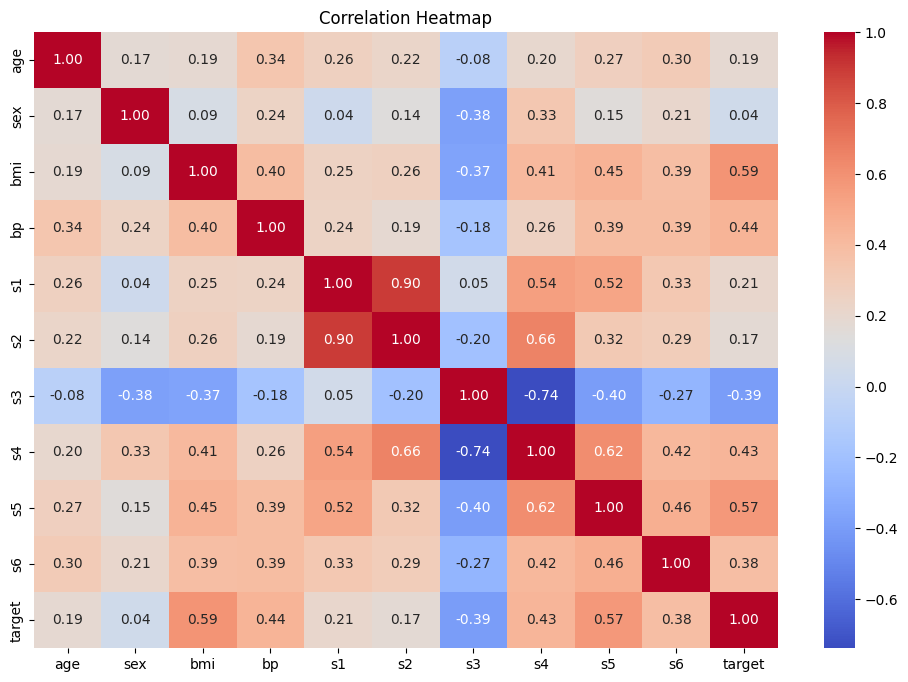

In [ ]:
# Correlation heatmap
plt.figure(figsize=(12, 8))

sns.heatmap(
    df.corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap")
plt.show()

In [ ]:
# Select independent and dependent variables
X = df[['bmi']]
y = df['target']

# Split dataset into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train the model
simple_model = LinearRegression()
simple_model.fit(X_train, y_train)

# Make predictions
y_pred_simple = simple_model.predict(X_test)

# Evaluate model
r2_simple = r2_score(y_test, y_pred_simple)

rmse_simple = np.sqrt(
    mean_squared_error(y_test, y_pred_simple)
)

print("Simple Linear Regression Results")
print("--------------------------------")
print("Intercept:", simple_model.intercept_)
print("Coefficient:", simple_model.coef_[0])
print("R2 Score:", r2_simple)
print("RMSE:", rmse_simple)

Simple Linear Regression Results
--------------------------------
Intercept: 152.00335421448167
Coefficient: 998.5776891375598
R2 Score: 0.23335039815872138
RMSE: 63.73245584860925


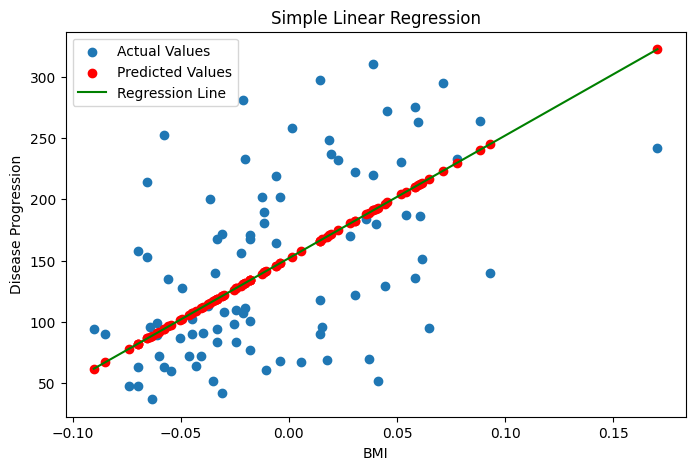

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(X_test['bmi'], y_test, label='Actual Values')

plt.scatter(
    X_test['bmi'],
    y_pred_simple,
    color='red',
    label='Predicted Values'
)

# Regression line
sorted_indices = np.argsort(X_test['bmi'].values)

plt.plot(
    X_test['bmi'].values[sorted_indices],
    y_pred_simple[sorted_indices],
    color='green',
    label='Regression Line'
)

plt.xlabel("BMI")
plt.ylabel("Disease Progression")
plt.title("Simple Linear Regression")
plt.legend()
plt.show()

In [ ]:
# Select all independent variables
X = df.drop('target', axis=1)

# Dependent variable
y = df['target']

# Split dataset
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Create and train model
multiple_model = LinearRegression()
multiple_model.fit(X_train, y_train)

# Make predictions
y_pred_multiple = multiple_model.predict(X_test)

# Evaluate model
r2_multiple = r2_score(y_test, y_pred_multiple)

rmse_multiple = np.sqrt(
    mean_squared_error(y_test, y_pred_multiple)
)

print("Multiple Linear Regression Results")
print("----------------------------------")
print("Intercept:", multiple_model.intercept_)

print("\nCoefficients:")
for feature, coefficient in zip(
    X.columns, multiple_model.coef_
):
    print(feature, ":", coefficient)

print("\nR2 Score:", r2_multiple)
print("RMSE:", rmse_multiple)

Multiple Linear Regression Results
----------------------------------
Intercept: 151.34560453985995

Coefficients:
age : 37.904021350074984
sex : -241.96436231273995
bmi : 542.4287585162899
bp : 347.70384391385636
s1 : -931.4888458835163
s2 : 518.0622769833376
s3 : 163.41998299131035
s4 : 275.3179015786484
s5 : 736.1988589046839
s6 : 48.67065743196543

R2 Score: 0.4526027629719195
RMSE: 53.85344583676593


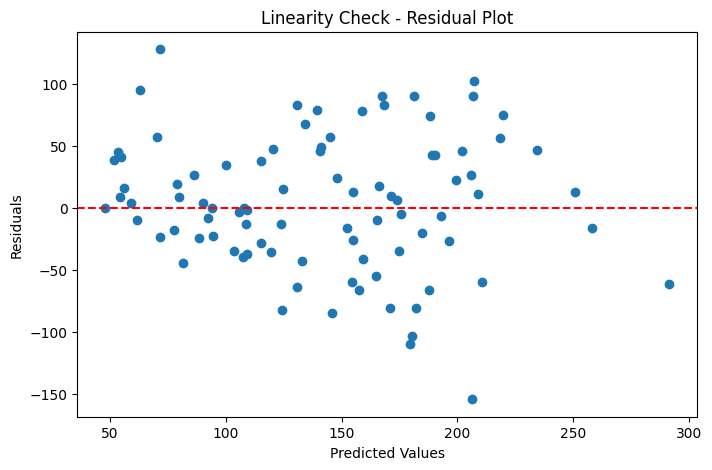

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(y_pred_multiple, y_test - y_pred_multiple)

plt.axhline(y=0, color='red', linestyle='--')

plt.xlabel("Predicted Values")
plt.ylabel("Residuals")

plt.title("Linearity Check - Residual Plot")
plt.show()

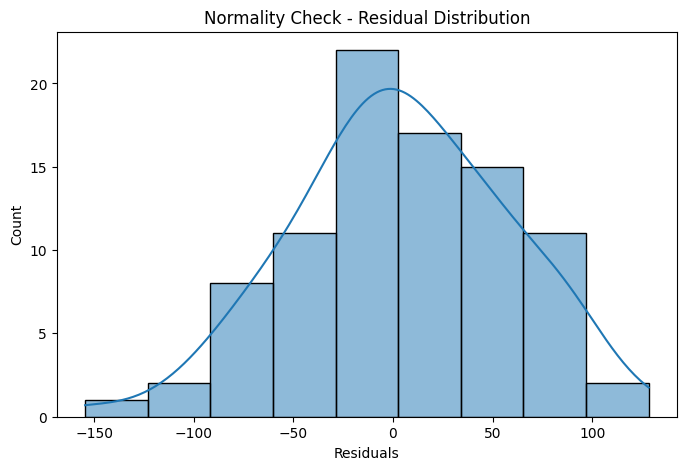

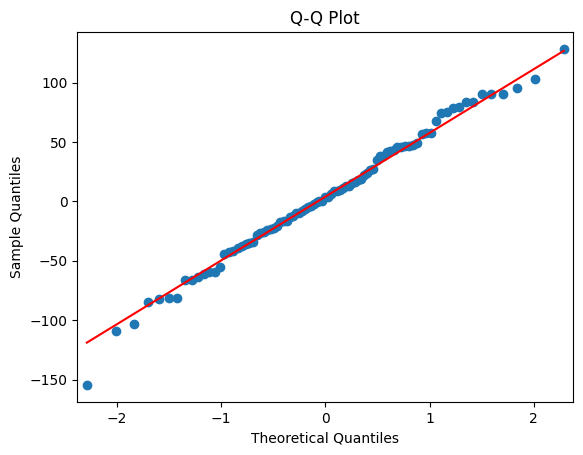

In [ ]:
residuals = y_test - y_pred_multiple

plt.figure(figsize=(8, 5))

sns.histplot(residuals, kde=True)

plt.title("Normality Check - Residual Distribution")
plt.xlabel("Residuals")
plt.show()

# Q-Q Plot
sm.qqplot(residuals, line='s')

plt.title("Q-Q Plot")
plt.show()

In [ ]:
# Breusch-Pagan Test
X_train_sm = sm.add_constant(X_train)

ols_model = sm.OLS(y_train, X_train_sm).fit()

X_test_sm = sm.add_constant(X_test)

residuals_train = ols_model.resid

bp_test = het_breuschpagan(
    residuals_train,
    X_train_sm
)

print("Breusch-Pagan Test")
print("------------------")
print("LM Statistic:", bp_test[0])
print("LM P-value:", bp_test[1])

if bp_test[1] > 0.05:
    print("Homoscedasticity assumption is satisfied.")
else:
    print("Possible heteroscedasticity detected.")

Breusch-Pagan Test
------------------
LM Statistic: 19.484426818772036
LM P-value: 0.0345240300583147
Possible heteroscedasticity detected.


In [ ]:
X_vif = sm.add_constant(X)

vif_data = pd.DataFrame()

vif_data['Feature'] = X_vif.columns

vif_data['VIF'] = [
    variance_inflation_factor(
        X_vif.values, i
    )
    for i in range(X_vif.shape[1])
]

print("Variance Inflation Factor:")
display(vif_data)

Variance Inflation Factor:


,Feature,VIF
0,const,1.000000
1,age,1.217307
2,sex,1.278071
3,bmi,1.509437
4,bp,1.459428
5,s1,59.202510
6,s2,39.193370
7,s3,15.402156
8,s4,8.890986
9,s5,10.075967


In [ ]:
dw = durbin_watson(residuals_train)

print("Durbin-Watson Statistic:", dw)

if 1.5 <= dw <= 2.5:
    print("No strong evidence of autocorrelation.")
else:
    print("Possible autocorrelation detected.")

Durbin-Watson Statistic: 1.794076816566665
No strong evidence of autocorrelation.


In [ ]:
comparison = pd.DataFrame({
    'Model': [
        'Simple Linear Regression',
        'Multiple Linear Regression'
    ],
    'R2 Score': [
        r2_simple,
        r2_multiple
    ],
    'RMSE': [
        rmse_simple,
        rmse_multiple
    ]
})

print("Model Performance Comparison:")
display(comparison)

Model Performance Comparison:


,Model,R2 Score,RMSE
0,Simple Linear Regression,0.233350,63.732456
1,Multiple Linear Regression,0.452603,53.853446


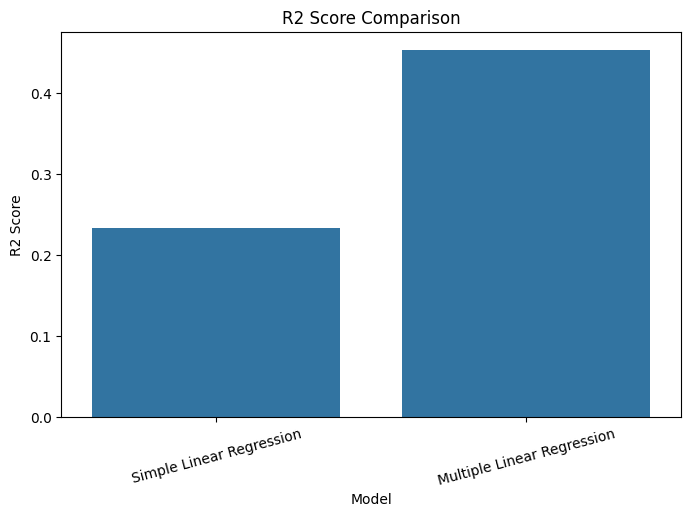

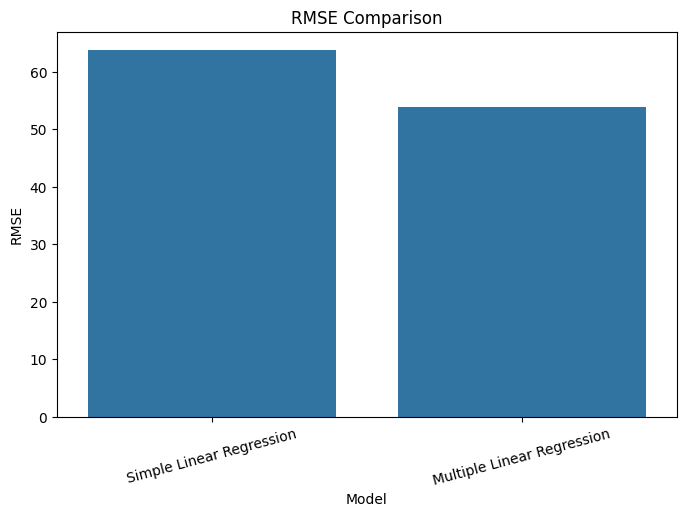

In [ ]:
# R2 Score Comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='R2 Score'
)

plt.title("R2 Score Comparison")
plt.xticks(rotation=15)
plt.show()


# RMSE Comparison
plt.figure(figsize=(8, 5))

sns.barplot(
    data=comparison,
    x='Model',
    y='RMSE'
)

plt.title("RMSE Comparison")
plt.xticks(rotation=15)
plt.show()

In [ ]:
print("FINAL RESULT")
print("============")

if r2_multiple > r2_simple:
    print("Multiple Linear Regression has a higher R2 score.")
else:
    print("Simple Linear Regression has a higher R2 score.")

if rmse_multiple < rmse_simple:
    print("Multiple Linear Regression has lower prediction error.")
else:
    print("Simple Linear Regression has lower prediction error.")

print("\nSimple Linear Regression:")
print("R2 Score:", round(r2_simple, 4))
print("RMSE:", round(rmse_simple, 4))

print("\nMultiple Linear Regression:")
print("R2 Score:", round(r2_multiple, 4))
print("RMSE:", round(rmse_multiple, 4))

FINAL RESULT
Multiple Linear Regression has a higher R2 score.
Multiple Linear Regression has lower prediction error.

Simple Linear Regression:
R2 Score: 0.2334
RMSE: 63.7325

Multiple Linear Regression:
R2 Score: 0.4526
RMSE: 53.8534
